<a href="https://colab.research.google.com/github/zcflanzer/rcew-water-budget/blob/main/SWE_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# mean annual RCEW SWE

Author: Zoe Flanzer\
Last updated: 5/22/2026\
Purpose: To make csv's of mean catchment SWE for each water year.\
Data: https://nsidc.org/data/wus_ucla_sr/versions/1


In [1]:
## setting up notebook
# mounting google drive
from google.colab import drive
drive.mount('/content/drive')

# installing important libraries
!pip install cartopy
import cartopy
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import datetime
import xarray as xr
import geopandas as gpd
from shapely.geometry import Point

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 46.7 MB/s eta 0:00:00


In [3]:
# loading data
# snow data (.nc file)
nc_path = "/content/drive/MyDrive/THESIS/data/Snow/SWE/.nc_files/WUS_UCLA_SR_v01_N43_0W117_0_agg_16_WY2011_12_SWE_SCA_POST.nc"
ds = xr.open_dataset(nc_path)

# study area (.shp file)
shp_path = "/content/drive/MyDrive/THESIS/data/Shapefiles/tollgate.shp"
gdf = gpd.read_file(shp_path)
gdf = gdf.to_crs("EPSG:4326") # reprojecting to match .nc file

# study/file year
year = '2011'  # ****** change when file path is changed ******

/tmp/ipykernel_2232/230407412.py:12: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf.geometry.unary_union.centroid


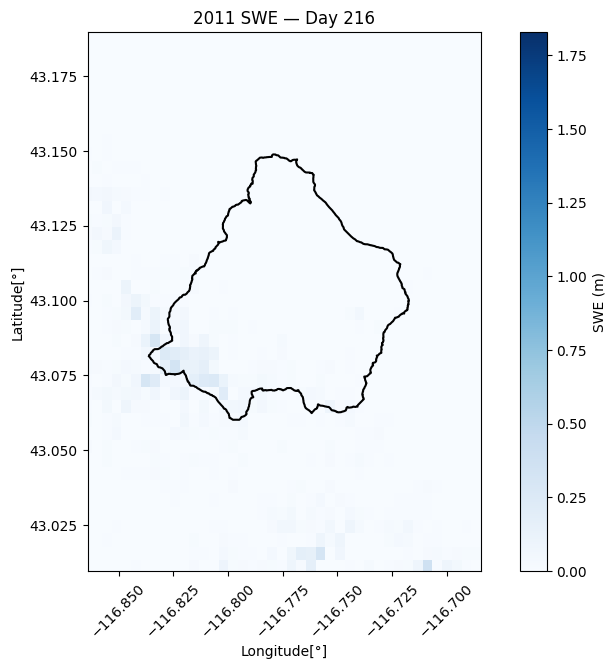

In [34]:
## mapping one day of data
day_index = 216 # day of year that's being mapped
stat_index = 0
da_day = ds["SWE_Post"].isel(Day=day_index, Stats=stat_index)

# lon/lat coordinates
da_day = da_day.assign_coords(lon=("Longitude", ds["Longitude"].values),lat=("Latitude", ds["Latitude"].values))
da_day = da_day.swap_dims({"Longitude": "lon", "Latitude": "lat"}) # swapping dimensions so lon/lat becomes dimansion names
da_day = da_day.transpose("lat", "lon") # reordering lat/lon so xarray plots correctly

# compute shapefile centroid
centroid = gdf.geometry.unary_union.centroid
cx, cy = centroid.x, centroid.y

# defining zoom window
buffer_deg = 0.09 # smaller value = zoomed in, larger value = zoomed out

x_min = cx - buffer_deg
x_max = cx + buffer_deg
y_min = cy - buffer_deg
y_max = cy + buffer_deg

# compute peak SWE for the entire year (across all days & grid cells)
year_peak_swe = float(np.nanmax(ds["SWE_Post"].isel(Stats=stat_index).values))

# Set global vmin/vmax for plotting
vmin_global = 0
vmax_global = year_peak_swe # keeping max y-axis consistent with peak SWE

# plotting
fig, ax = plt.subplots(figsize=(10, 7))
mappable = da_day.plot(ax=ax,cmap="Blues",vmin=vmin_global,vmax=vmax_global)
gdf.boundary.plot(ax=ax, color="black", linewidth=1.5) # adding catchment/shapefile outline

# Zoom to centroid window
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.tick_params(axis="x", rotation=45)

# formatting
cbar = mappable.colorbar
cbar.set_label("SWE (m)")
ax.set_title(f"{year} SWE — Day {day_index}")
ax.set_xlabel("Longitude[\N{DEGREE SIGN}]")
ax.set_ylabel("Latitude[\N{DEGREE SIGN}]")

plt.show()

/tmp/ipykernel_2232/4191188381.py:10: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf.geometry.unary_union.centroid


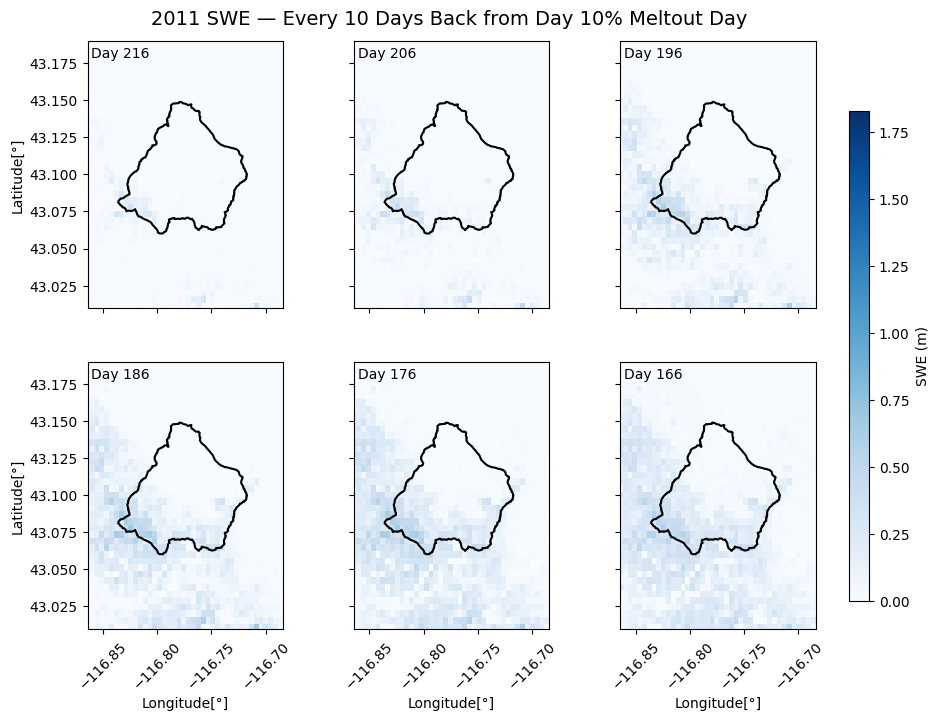

In [35]:
## putting 60 days prior to meltout in one plot
final_day = 216 # last day being shown
step_days = 10 # spacing between days
nplots = 6 # 6 subplots

stat_index = 0
days_to_plot = [final_day - i * step_days for i in range(nplots)]

# centroid
centroid = gdf.geometry.unary_union.centroid
cx, cy = centroid.x, centroid.y

buffer_deg = 0.09
x_min = cx - buffer_deg
x_max = cx + buffer_deg
y_min = cy - buffer_deg
y_max = cy + buffer_deg

# peak swe and y-axis variables
year_peak_swe = float(np.nanmax(ds["SWE_Post"].isel(Stats=stat_index).values))
vmin_global = 0
vmax_global = year_peak_swe

# plotting
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
axes = axes.flatten()
fig.subplots_adjust(right=0.88, top=0.95) # moving over for colorbar

mappable = None

# looping over days
for ax, day_index in zip(axes, days_to_plot):
    da_day = ds["SWE_Post"].isel(Day=day_index, Stats=stat_index)
    da_day = da_day.assign_coords(lon=("Longitude", ds["Longitude"].values),lat=("Latitude", ds["Latitude"].values))
    da_day = da_day.swap_dims({"Longitude": "lon", "Latitude": "lat"})
    da_day = da_day.transpose("lat", "lon")
    mappable = da_day.plot(ax=ax,cmap="Blues",vmin=vmin_global,vmax=vmax_global,add_colorbar=False)
    gdf.boundary.plot(ax=ax, color="black", linewidth=1.5)

    # axis limits
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.tick_params(axis="x", rotation=45)

    # labeling
    ax.text(0.02, 0.98,f"Day {day_index}",transform=ax.transAxes,ha="left", va="top",fontsize=10,bbox=dict(facecolor="none", edgecolor="none", alpha=0.6)) # adding day to subplots
    ax.set_xlabel("Longitude[\N{DEGREE SIGN}]")
    ax.set_ylabel("Latitude[\N{DEGREE SIGN}]")

    # only show lat ticks on farthest left column
    if ax in axes[0::3]:
        ax.set_ylabel("Latitude[°]")
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])

    # only show long ticks on bottom row
    if ax in axes[-3:]:    # axes 3, 4, 5 (bottom row)
       ax.set_xlabel("Longitude[°]")
    else:
        ax.set_xlabel("")
        ax.set_xticklabels([])

# adding colorbar
cax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(mappable, cax=cax)
cbar.set_label("SWE (m)")

# title
fig.text(0.5, 0.995,f"{year} SWE — Every {step_days} Days Back from Day 10% Meltout Day",ha="center", va="top", fontsize=14)

plt.show()


In [36]:
## creating df of catchment mean SWE
swe = ds["SWE_Post"].isel(Stats=0)

# lon/lat coordinates
swe = swe.assign_coords(lon=("Longitude", ds["Longitude"].values),lat=("Latitude", ds["Latitude"].values))
swe = swe.swap_dims({"Longitude": "lon", "Latitude": "lat"})
swe = swe.transpose("Day", "lat", "lon")

# build a mask of pixels inside the shapefile polygon
poly = gdf.geometry.unary_union  # merged polygon

# create 2D lon/lat grids
lon2d, lat2d = np.meshgrid(swe.lon.values, swe.lat.values)

# vectorized point-in-polygon test
mask = np.vectorize(lambda x, y: poly.contains(Point(x, y)))(lon2d, lat2d)
mask = mask.astype(bool) # boolean array

# compute mean SWE for each day
mean_values = []
for i in range(swe.sizes["Day"]):
    arr = swe.isel(Day=i).values
    mean_values.append(np.nanmean(arr[mask]))

# build table
df = pd.DataFrame({
    "Day": ds["Day"].values,
    "Mean_SWE": mean_values
})

df

/tmp/ipykernel_2232/1978397236.py:10: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  poly = gdf.geometry.unary_union  # merged polygon


,Day,Mean_SWE
0,0,0.000000
1,1,0.000000
2,2,0.000000
3,3,0.000000
4,4,0.000214
...,...,...
361,361,0.000000
362,362,0.000000
363,363,0.000000
364,364,0.000000


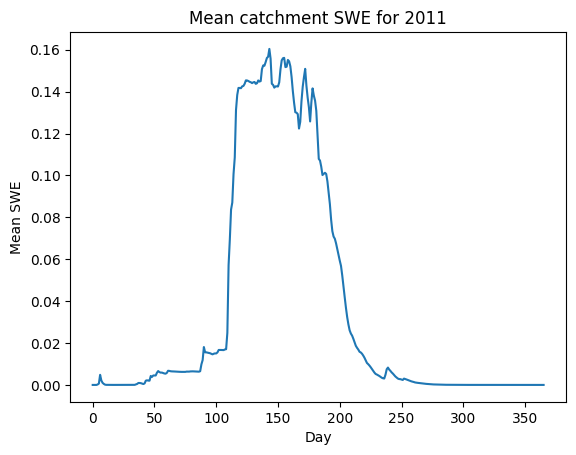

In [37]:
## plotting and saving SWE data
# convert df to a markdown table and save as csv
markdown_table = df.to_markdown(index=False)
#df.to_csv(f"swe_timeseries_mean_{year}.csv", index=False) # saving df as csv
#print("\nSaved locally as swe_timeseries_mean.csv")

# plotting
plt.plot(df['Day'], df['Mean_SWE'])
plt.xlabel('Day')
plt.ylabel('Mean SWE')
plt.title(f'Mean catchment SWE for {year}')
plt.show()